# SoK: Randomness Failures and Their Remedies -- Analysis Notebook

This notebook backs the quantitative claims in the paper. Every figure used in the text is
recomputed here, and each result carries an `assert` so the notebook self-verifies.

Contents:

1. Effective entropy vs. brute-force cost (the published ColdCard estimates of 32, 40.7, and 72 bits).
2. Conditioning cannot add entropy (hashed output looks uniform yet stays predictable).
3. ECDSA nonce-reuse key recovery on secp256k1 (the consumption-stage failures).
4. Cost amortization across a victim population (why one defect sweeps an ecosystem).

All computations use the Python standard library; only matplotlib is external.

In [1]:
import math, hashlib
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display

# secp256k1 group order (n) and field prime (p)
n = 0xFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFEBAAEDCE6AF48A03BBFD25E8CD0364141
p = 0xFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFEFFFFFC2F
print('secp256k1 order bit-length:', n.bit_length())

secp256k1 order bit-length: 256


## 1. Effective entropy vs. brute-force cost

A seed with `H` bits of min-entropy ranges over at most `2**H` values. An attacker who can
reproduce the seed inputs enumerates those candidates and, for each, derives an address to test
against the public chain. Expected work is about `2**(H-1)` derivations. For ColdCard the published
analyses differ. The vendor estimates about 40 bits on the Mk2/Mk3 and about 72 bits on the
Mk4/Mk5/Q; Block bounds the Mk2/Mk3 near 40.7 bits and counts at most 2**32 output streams on the
later models once the fallback state and call history are fixed. We compute the cost at all three.

In [2]:
def expected_time_seconds(H, rate):
    '''Expected brute-force time = (2**H / 2) / rate derivations per second.'''
    return (2.0**H / 2.0) / rate

scenarios = {
    'Mk4/Mk5/Q (Block, fixed state)': 32.0,
    'Mk2/Mk3 (upper bound)': 40.7,
    'Mk4/Mk5/Q (vendor estimate)': 72.0,
    'Design target': 128.0,
}
rates = {'single accelerator (1e6/s)': 1e6, 'cluster (1e8/s)': 1e8}

print(f"{'scenario':30s} {'H':>6} {'rate':>26} {'exp. time':>16}")
for label, H in scenarios.items():
    for rlabel, r in rates.items():
        t = expected_time_seconds(H, r)
        if t < 3600:      human = f'{t:8.1f} s'
        elif t < 86400:   human = f'{t/3600:8.2f} h'
        elif t < 3.15e7:  human = f'{t/86400:8.2f} d'
        else:             human = f'{t/3.15e7:8.2e} yr'
        print(f'{label:30s} {H:6.1f} {rlabel:>26} {human:>16}')

# Assertions matching the paper's appendix
assert abs(expected_time_seconds(32, 1e6) - 2147.48) < 1.0     # ~36 minutes
assert abs(expected_time_seconds(40.7, 1e6)/86400 - 10.34) < 0.05  # ~10 days
assert abs(expected_time_seconds(72, 1e8)/3.15576e7 - 7.48e5) < 0.01e5  # ~7.5e5 years
assert expected_time_seconds(128, 1e8) > 1e29                  # infeasible
print('\nAssertions passed: 2^31/1e6 ~= 36 min, 2^39.7/1e6 ~= 10 days, 2^71/1e8 ~= 7.5e5 years, 2^128 infeasible.')

scenario                            H                       rate        exp. time
Mk4/Mk5/Q (Block, fixed state)   32.0 single accelerator (1e6/s)         2147.5 s
Mk4/Mk5/Q (Block, fixed state)   32.0            cluster (1e8/s)           21.5 s
Mk2/Mk3 (upper bound)            40.7 single accelerator (1e6/s)          10.34 d
Mk2/Mk3 (upper bound)            40.7            cluster (1e8/s)           2.48 h
Mk4/Mk5/Q (vendor estimate)      72.0 single accelerator (1e6/s)      7.50e+07 yr
Mk4/Mk5/Q (vendor estimate)      72.0            cluster (1e8/s)      7.50e+05 yr
Design target                   128.0 single accelerator (1e6/s)      5.40e+24 yr
Design target                   128.0            cluster (1e8/s)      5.40e+22 yr

Assertions passed: 2^31/1e6 ~= 36 min, 2^39.7/1e6 ~= 10 days, 2^71/1e8 ~= 7.5e5 years, 2^128 infeasible.


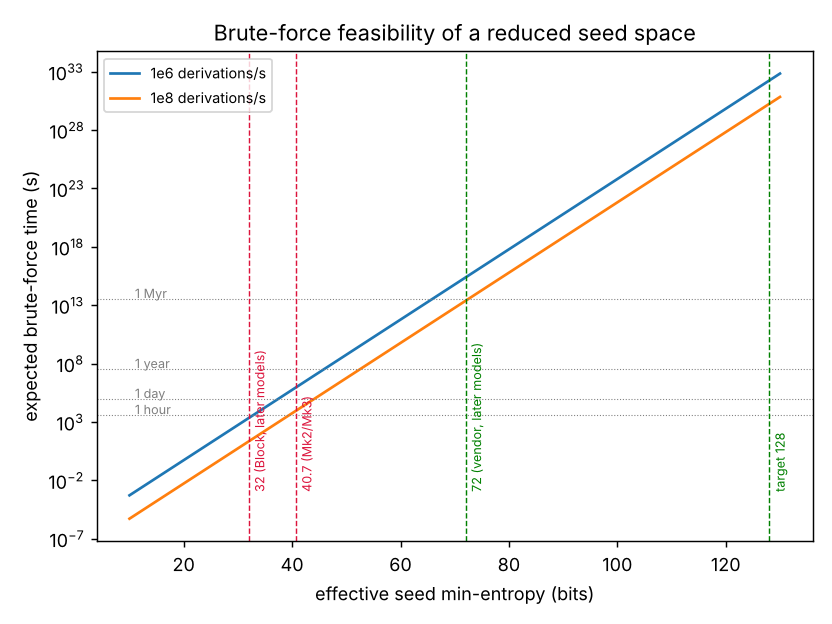

In [3]:
# Feasibility figure: brute-force time vs entropy bits
Hs = [i/2 for i in range(20, 261)]  # 10..130 bits
for rlabel, r in [('1e6 derivations/s', 1e6), ('1e8 derivations/s', 1e8)]:
    plt.plot(Hs, [expected_time_seconds(H, r) for H in Hs], label=rlabel)
plt.yscale('log')
for sec, name in [(3600,'1 hour'), (86400,'1 day'), (3.15e7,'1 year'), (3.15e7*1e6,'1 Myr')]:
    plt.axhline(sec, color='grey', lw=0.6, ls=':')
    plt.text(11, sec*1.3, name, fontsize=7, color='grey')
for H, name in [(32,'32 (Block, later models)'), (40.7,'40.7 (Mk2/Mk3)'), (72,'72 (vendor, later models)'), (128,'target 128')]:
    plt.axvline(H, color='crimson' if H<50 else 'green', lw=0.8, ls='--')
    plt.text(H+0.6, 1e-3, name, rotation=90, fontsize=7,
             color='crimson' if H<50 else 'green', va='bottom')
plt.xlabel('effective seed min-entropy (bits)')
plt.ylabel('expected brute-force time (s)')
plt.title('Brute-force feasibility of a reduced seed space')
plt.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('figures/bruteforce.pdf')
plt.savefig('figures/bruteforce.png', dpi=130)
plt.close()
display(Image('figures/bruteforce.png'))

## 2. Conditioning cannot add entropy

Hashing makes output look uniform, but a deterministic function cannot enlarge the set of possible values: hashing `N` possible
seeds yields at most `N` possible outputs. We demonstrate with a small family.

In [4]:
def sha256d(b):
    return hashlib.sha256(hashlib.sha256(b).digest()).digest()

family = 5000                      # a small seed family (stands in for a 2**H space)
outputs = {sha256d(i.to_bytes(4,'big')) for i in range(family)}
print('distinct seeds in :', family)
print('distinct outputs  :', len(outputs))
assert len(outputs) == family, 'hashing must not change the count of reachable values'
print('Confirmed: SHA-256d yields exactly as many outputs as inputs; no entropy is added.')

distinct seeds in : 5000
distinct outputs  : 5000
Confirmed: SHA-256d yields exactly as many outputs as inputs; no entropy is added.


## 3. ECDSA nonce-reuse key recovery (secp256k1)

If one private key signs two messages with the same nonce `k`, the signatures share `r`, and
the key falls out algebraically with no search:

$$k = \frac{h_1 - h_2}{s_1 - s_2} \bmod n, \qquad d = \frac{s_1 k - h_1}{r} \bmod n.$$

We implement secp256k1 from scratch, sign two messages with a deliberately reused nonce, and
recover the private key exactly.

In [5]:
Gx = 0x79BE667EF9DCBBAC55A06295CE870B07029BFCDB2DCE28D959F2815B16F81798
Gy = 0x483ADA7726A3C4655DA4FBFC0E1108A8FD17B448A68554199C47D08FFB10D4B8
G = (Gx, Gy)

def inv(a, m): return pow(a % m, m - 2, m)
def ec_add(P, Q):
    if P is None: return Q
    if Q is None: return P
    if P[0] == Q[0] and (P[1] + Q[1]) % p == 0: return None
    if P == Q: lam = (3 * P[0] * P[0]) * inv(2 * P[1], p) % p
    else:      lam = (Q[1] - P[1]) * inv(Q[0] - P[0], p) % p
    x = (lam * lam - P[0] - Q[0]) % p
    return (x, (lam * (P[0] - x) - P[1]) % p)
def ec_mul(k, P):
    R = None
    while k:
        if k & 1: R = ec_add(R, P)
        P = ec_add(P, P); k >>= 1
    return R

def sign(d, k, msg):
    h = int.from_bytes(hashlib.sha256(msg).digest(), 'big') % n
    r = ec_mul(k, G)[0] % n
    s = (inv(k, n) * (h + r * d)) % n
    return h, r, s

d_true = 0x1234567890ABCDEF1122334455667788      # the victim's secret key
k_reused = 0xC0FFEE1234567890FEDCBA9876543210      # BUG: same nonce for both signatures
h1, r1, s1 = sign(d_true, k_reused, b'transfer 1 BTC to Alice')
h2, r2, s2 = sign(d_true, k_reused, b'transfer 2 BTC to Bob')

assert r1 == r2, 'reused nonce => identical r (the on-chain tell)'
k_rec = ((h1 - h2) * inv((s1 - s2) % n, n)) % n
d_rec = ((s1 * k_rec - h1) * inv(r1, n)) % n
print('shared r (hex):', hex(r1))
print('recovered nonce k == true k :', k_rec == k_reused)
print('recovered key   d == true d :', d_rec == d_true)
print('recovered private key       :', hex(d_rec))
assert k_rec == k_reused and d_rec == d_true
print('\nA single repeated nonce, visible on a public ledger, discloses the key directly.')

shared r (hex): 0xe604ffd42ca7d36a499f00cb9aca367163915dc5d2777d3e6207a67cec46fe90
recovered nonce k == true k : True
recovered key   d == true d : True
recovered private key       : 0x1234567890abcdef1122334455667788

A single repeated nonce, visible on a public ledger, discloses the key directly.


## 4. Cost amortization across a victim population

Appendix C claims that an attacker enumerating a reduced seed space tests each candidate against
the entire population of funded identifiers at once, so the cost is amortized across all victims
rather than paid per wallet. That claim is worth measuring rather than asserting.

We model it abstractly and synthetically: candidates and targets are hashes of integers, with no
BIP-39 or BIP-32 derivation and no real addresses. The question is purely about scaling. If
membership testing is a constant-time set lookup, enumeration throughput should be effectively
flat in the number of targets, which is what makes a single defect a population-scale sweep.

In [6]:
import time

def target_set(n):
    # synthetic stand-in for a set of funded identifiers
    return {hashlib.sha256(b'target-%d' % i).digest()[:8] for i in range(n)}

def enumerate_against(targets, candidates):
    # enumerate candidates, testing each for membership; returns (hits, seconds)
    t0 = time.perf_counter()
    hits = 0
    for i in range(candidates):
        d = hashlib.sha256(b'target-%d' % i).digest()[:8]
        if d in targets:
            hits += 1
    return hits, time.perf_counter() - t0

CANDIDATES = 200_000
rows = []
for n in (1, 10**3, 10**5, 10**6):
    hits, secs = enumerate_against(target_set(n), CANDIDATES)
    rows.append((n, hits, secs, CANDIDATES / secs))

print('%10s %8s %9s %14s' % ('targets','hits','seconds','candidates/s'))
for n, hits, secs, rate in rows:
    print('%10d %8d %9.3f %14.0f' % (n, hits, secs, rate))

ratio = rows[0][3] / rows[-1][3]
print('\nthroughput at 1 target vs %d targets: %.2fx' % (rows[-1][0], ratio))
assert ratio < 3.0, 'membership testing should be near constant-time in the target count'
print('Confirmed: enumeration cost is governed by the candidate space, not the victim count.')
print('One defect therefore harvests an entire population for essentially the price of one.')

   targets     hits   seconds   candidates/s
         1        1     0.110        1819453
      1000     1000     0.124        1613819
    100000   100000     0.139        1434110
   1000000   200000     0.150        1333570

throughput at 1 target vs 1000000 targets: 1.36x
Confirmed: enumeration cost is governed by the candidate space, not the victim count.
One defect therefore harvests an entire population for essentially the price of one.


## Summary

Seed spaces of 2**32 and 2**40.7, the smaller published ColdCard estimates, are exhaustible in
minutes to days on modest hardware, while 72 bits, the vendor's estimate for later models, and the
128-bit design target are not. Statistical uniformity from hashing does not help the defender, because
conditioning cannot enlarge the space of reachable seeds. And at the consumption stage, a single
reused ECDSA nonce discloses the private key with no search at all. And because membership
testing is constant-time in the number of targets, enumeration cost is set by the candidate
space alone, so one defect harvests a whole population for the price of one. These are the numbers cited
in Section 4 and Appendix C of the paper.